# Compare features between groups - from table

This notebook helps to perform feature comparison between two or more groups. The data is read from an Excel table.

A column of the table can be used to create "comparison groups".

## Initialization - don't change

In [17]:
import sys
sys.path.append('..')

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from workflows.run_util.io import collect_results_from_table
from param_classes.workflows.episode_analysis import GroupwiseComparisonParams
from workflows.episode_analysis import run_comparison, create_groups

params = GroupwiseComparisonParams()

## Color settings

Set the marker shapes that will be used for the scatter and the strip plot.

 - `shape_column`: name of the column to use to determine the marker shape
 - `shapes`: mapping of the column values to marker shapes

In [18]:
marker_shape_column = 'celltype'
marker_shapes = {
    'PYR': '^',
    'RSI': 'd',
    'FSI': 'o'
}

Set the colors that will be used for coloring the markers on the scatter and the strip plot.

 - `color_column`: name of the column to use to determine the marker shape
 - `colors`: mapping of the column values to marker shapes

In [19]:
marker_color_column = 'group'
marker_colors = {
    'PYR_L2-3': '#803300ff',
    'PYR_L4-6': '#502d16ff',
    'RSI_L2-3': '#ff48a3ff',
    'RSI_L4-6': '#800080ff',
    'FSI_L2-3': '#d54500ff',
    'FSI_L4-6': '#7a0000ff'
}

## Input-output settings

In [20]:
table_path = 'C:/tmp/Bozso2025/PutRAAP/Results/New/data_invivo.xlsx'

## Analysis parameters

### Comparison groups

You can set a feature by which the script forms "comparison groups". Only groups within a comparison group will be statistically compared. If you set `grouping_column` to None, the whole table is a single comparison group.

If you provide a column name, you can list the groups that you want to use for comparison. If you leave `group_list` empty, all unique value in that column will result in a comparison group.

In [21]:
grouping_column = None
group_list = []

You have to set the column name that is used to determine groups (within a *comparison group* if given) to compare to each other. You can provide a list of groups in `comparison_list` (have to be at least 2) you want to compare to each other.

If you give more than 2 groups, a preliminary *Kruskal-Wallis* test will be performed. If that is significant, a post-hoc, multiple comparison test will be performed with Holm correction.

In [22]:
comparison_column = 'celltype'
comparison_list = ['FSI', 'RSI', 'PYR']

In [23]:
features = ['frequency', 'halfwidth']

## Run analysis

Load data

In [24]:
data = pd.read_excel(table_path)

Create comparison groups

In [25]:
if grouping_column is not None:
    if len(group_list) == 0:
        group_list = data[grouping_column].unique().tolist()
    groups = [(g, data[data[grouping_column] == g]) for g in group_list]
else:
    groups = [('', data)]

In [46]:
from scipy.stats import kruskal, ranksums
from statsmodels.stats.multitest import multipletests
from itertools import combinations

for group_name, group_data in groups:
    if len(comparison_list) == 0:
        comparison_list = group_data[comparison_column].unique().tolist()
    if len(comparison_list) < 2:
        print(f"Not enough groups to compare in column '{comparison_column}'. Skipping.")
        continue
    print(f"Group: {group_name}")
    subset = group_data[group_data[comparison_column].isin(comparison_list)]
    for feature in features:
        if len(comparison_list) == 2:
            group1 = subset[subset[comparison_column] == comparison_list[0]][feature]
            group2 = subset[subset[comparison_column] == comparison_list[1]][feature]
            stat, p_value = ranksums(group1, group2)
            print(f"\tFeature: {feature}, Statistic: {stat}, p-value: {p_value}")
        else:
            data_groups = [subset[subset[comparison_column] == g][feature] for g in comparison_list]
            stat, p_value = kruskal(*data_groups)
            print(f"\tFeature: {feature}, Statistic: {stat}, p-value: {p_value}")
            # Post-hoc tests if Kruskal-Wallis is significant
            if len(comparison_list) > 2 and p_value < 0.05:
                post_hoc_results = []
                for g1, g2 in combinations(comparison_list, 2):
                    group1 = subset[subset[comparison_column] == g1][feature]
                    group2 = subset[subset[comparison_column] == g2][feature]
                    stat, p_value = ranksums(group1, group2)
                    post_hoc_results.append((g1, g2, stat, p_value))
                reject, pvals_corrected = multipletests(
                    [res[3] for res in post_hoc_results], method='holm'
                )[:2]
                for i, (g1, g2, stat, p_value) in enumerate(post_hoc_results):
                    print(f"\t\tPost-hoc: {g1} vs {g2}, Statistic: {stat}, p-value: {p_value}, Corrected p-value: {pvals_corrected[i]}, Reject H0: {reject[i]}")


Group: 
	Feature: frequency, Statistic: 227.203235562878, p-value: 4.607276346787768e-50
		Post-hoc: FSI vs RSI, Statistic: 8.407346658649166, p-value: 4.1939013107761234e-17, Corrected p-value: 4.1939013107761234e-17, Reject H0: True
		Post-hoc: FSI vs PYR, Statistic: 10.472671860380068, p-value: 1.1534070240547228e-25, Corrected p-value: 2.3068140481094456e-25, Reject H0: True
		Post-hoc: RSI vs PYR, Statistic: 12.407824903777746, p-value: 2.3700403258413743e-35, Corrected p-value: 7.110120977524123e-35, Reject H0: True
	Feature: halfwidth, Statistic: 151.02213810298537, p-value: 1.6067909919956683e-33
		Post-hoc: FSI vs RSI, Statistic: -6.029973431700336, p-value: 1.6398663600111359e-09, Corrected p-value: 1.6398663600111359e-09, Reject H0: True
		Post-hoc: FSI vs PYR, Statistic: -9.883490249505842, p-value: 4.9092580188834695e-23, Corrected p-value: 1.472777405665041e-22, Reject H0: True
		Post-hoc: RSI vs PYR, Statistic: -9.007043007570806, p-value: 2.1168707150471984e-19, Correct

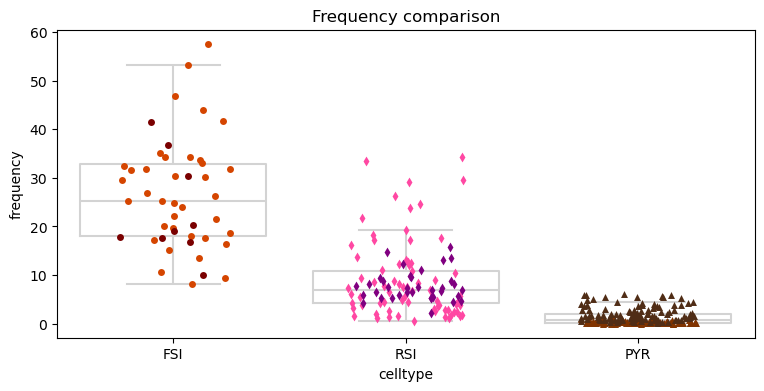

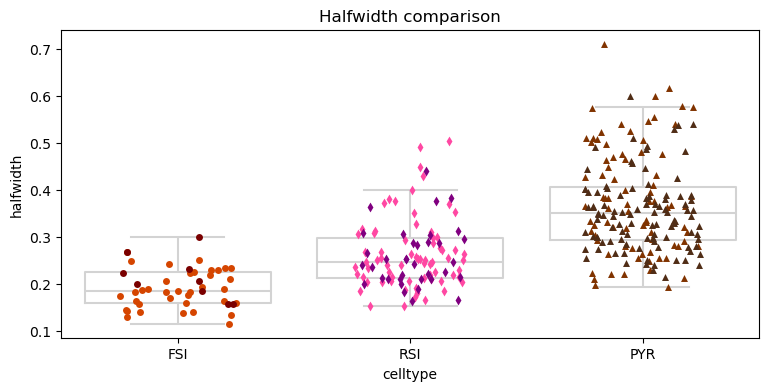

In [ ]:
for group_name, group_data in groups:
    if len(comparison_list) == 0:
        comparison_list = group_data[comparison_column].unique().tolist()
    if len(comparison_list) < 2:
        print(f"Not enough groups to compare in column '{comparison_column}'. Skipping.")
        continue
    subset = group_data[group_data[comparison_column].isin(comparison_list)]
    subset[comparison_column] = pd.Categorical(
        subset[comparison_column],
        categories=comparison_list,
        ordered=True
    )
    for feature in features:
        fig, ax = plt.subplots(figsize=(3 * len(comparison_list), 4))
        sns.boxplot(
            data=subset,
            x=comparison_column,
            y=feature,
            color='lightgray',
            fill=False,
            fliersize=0,
            ax=ax
        )
        for color_group in subset[marker_color_column].unique():
            group_color = marker_colors.get(color_group, 'black')
            for marker_group in subset[marker_shape_column].unique():
                group_shape = marker_shapes.get(marker_group, 'o')
                plot_sub_data = subset[
                    (subset[marker_color_column] == color_group) &
                    (subset[marker_shape_column] == marker_group)
                ]
                sns.stripplot(
                    data=plot_sub_data,
                    x=comparison_column,
                    y=feature,
                    color=group_color,
                    marker=group_shape,
                    jitter=0.25,
                    s=5
                )
        ax.legend([],[], frameon=False)
        group_title = f' - {group_name}' if group_name else ''
        ax.set_title(f'{feature.capitalize()} comparison{group_title}')
        plt.show()

In [ ]:

figsize = (2 * config['plot']['axis_size'][0], config['plot']['axis_size'][1])
fig, axs = plt.subplots(1, 2, figsize=figsize)
for i, layer in enumerate(data['layer'].unique()):
    layer_data = data[data['layer'] == layer]
    sns.scatterplot(
        data=layer_data,
        x='halfwidth',
        y='frequency',
        hue='group',
        style='cell_type',
        ax=axs[i],
        palette=config['markers']['colors'],
        markers=config['markers']['shapes'],
        s=config['plot']['point_sizes'],
        edgecolor=None  # Remove edge color
    )

    handles, labels = axs[i].get_legend_handles_labels()
    components_to_keep = [
        (handle, label) for handle, label
        in zip(handles, labels)
        if label in config['markers']['colors']
    ]
    style_handles = [h for h, _ in components_to_keep]
    style_labels = [
        f"{l.split('_')[0]} (n={group_sizes[l]})"
        for _, l in components_to_keep
    ]

    axs[i].legend(
        style_handles,
        style_labels,
        title='Cell type',
        loc='lower right'
    )

    axs[i].set_xlim(config['plot']['axis_params']['limits']['x'])
    axs[i].set_ylim(config['plot']['axis_params']['limits']['y'])
    axs[i].set_title(f'Layer {layer}')
    axs[i].set_xlabel('Halfwidth (ms)')
    axs[i].set_ylabel('Firing Rate (Hz)')
    axs[i].set_xscale('log' if config['plot']['axis_params']['log_scale']['x'] else 'linear')
    axs[i].set_yscale('log' if config['plot']['axis_params']['log_scale']['y'] else 'linear')

plt.tight_layout()
extensions = ['png']
if config['output']['do_svg']:
    extensions.append('svg')
for ext in extensions:
    plt.savefig(
        (
            Path(config['output']['path']) /
            f"{config['output']['name']}.{ext}"
        ),
    dpi=config['output']['dpi']
)
plt.close(fig)